# 03 — So sánh các mô hình: Decision Tree, KNN, SVM và Random Forest

Notebook này tổng hợp và trực quan hóa kết quả từ:
- `python -m src.compare_datasets --dataset all --tune` (`model_comparison_long.csv`, `tuned_params.json`)
- `python -m src.model_stability` (`stability_summary.csv`, `stat_tests.csv`)

Nội dung:
1. Bảng kết quả chính trên dataset chính (`PRIMARY_DATASET = 'ibm'`, ngưỡng 0.5).
2. Bảng siêu tham số tốt nhất (`best_params`) của từng mô hình trên 3 dataset.
3. Heatmap mô hình × dataset theo `F1 (churn)` và `ROC-AUC`.
4. Biểu đồ cột 4 độ đo chính (`Accuracy`, `Precision`, `Recall`, `F1`) kèm error bar `mean ± std` qua 10 seed.
5. Tóm tắt kiểm định thống kê (`stat_tests.csv`).

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_ROOT = Path(os.environ.get('CHURN_OUTPUT_ROOT') or ROOT)
if not DATA_ROOT.is_absolute():
    DATA_ROOT = (ROOT / DATA_ROOT).resolve()

PRIMARY_DATASET = 'ibm'
RESULTS_DIR = DATA_ROOT / 'results'
MODELS_DIR = DATA_ROOT / 'models'
FIGURES_DIR = ROOT / 'figures' / 'models'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

long_csv = RESULTS_DIR / 'dataset_runs' / 'model_comparison_long.csv'
tuned_json = MODELS_DIR / 'tuned_params.json'
stability_csv = RESULTS_DIR / 'model_stability' / 'stability_summary.csv'
stat_tests_csv = RESULTS_DIR / 'model_stability' / 'stat_tests.csv'

for path in [long_csv, tuned_json, stability_csv, stat_tests_csv]:
    if not path.exists():
        raise FileNotFoundError(f'Missing {path}. Run compare_datasets --tune and model_stability first.')

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 140)
print('Data source:', DATA_ROOT)

Data source: C:\Users\nguye\OneDrive\Documents\NMKPDL_HM\projectML\results\scratch


## 1. Bảng so sánh chính trên dataset chính (ngưỡng 0.5)

In [2]:
long_df = pd.read_csv(long_csv)
cols = ['model', 'accuracy', 'precision_churn', 'recall_churn', 'f1_churn', 'roc_auc', 'average_precision']
primary_df = long_df[long_df['dataset'] == PRIMARY_DATASET][cols].copy()
primary_df = primary_df.rename(columns={
    'model': 'Model',
    'accuracy': 'Accuracy',
    'precision_churn': 'Precision (churn)',
    'recall_churn': 'Recall (churn)',
    'f1_churn': 'F1 (churn)',
    'roc_auc': 'ROC-AUC',
    'average_precision': 'PR-AUC (AP)',
})
primary_df.round(4)

,Model,Accuracy,Precision (churn),Recall (churn),F1 (churn),ROC-AUC,PR-AUC (AP)
0,Dummy,0.7351,0.0000,0.0000,0.0000,0.5000,0.2649
1,LogReg,0.8070,0.6712,0.5321,0.5936,0.8527,0.6723
2,DecisionTree,0.7540,0.5226,0.8250,0.6399,0.8491,0.6385
3,RandomForest,0.7682,0.5445,0.7643,0.6360,0.8513,0.6641
4,KNN,0.7881,0.6129,0.5429,0.5758,0.8377,0.6418
5,SVM_Linear,0.8127,0.6814,0.5500,0.6087,0.8523,0.6723
6,SVM_RBF,0.8089,0.6625,0.5679,0.6115,0.8476,0.6601


## 2. Siêu tham số tốt nhất (`best_params`) qua 5-fold CV (scoring = AP)

In [3]:
with open(tuned_json, encoding='utf-8') as f:
    tuned_payload = json.load(f)

param_rows = []
for ds, models in tuned_payload.get('runs', {}).items():
    for model_name, params in models.items():
        param_rows.append({
            'dataset': ds,
            'model': model_name,
            'best_params': json.dumps(params, ensure_ascii=False),
        })
params_df = pd.DataFrame(param_rows)
params_df

,dataset,model,best_params
0,ibm,LogReg,"{""C"": 5.0}"
1,ibm,DecisionTree,"{""min_samples_split"": 10, ""min_samples_leaf"": ..."
2,ibm,RandomForest,"{""n_estimators"": 500, ""min_samples_split"": 5, ..."
3,ibm,KNN,"{""weights"": ""uniform"", ""n_neighbors"": 51, ""met..."
4,ibm,SVM_Linear,"{""loss"": ""squared_hinge"", ""C"": 0.1}"
5,ibm,SVM_RBF,"{""gamma"": 0.001, ""C"": 5}"
6,iranian,LogReg,"{""C"": 10.0}"
7,iranian,DecisionTree,"{""min_samples_split"": 20, ""min_samples_leaf"": ..."
8,iranian,RandomForest,"{""n_estimators"": 100, ""min_samples_split"": 5, ..."
9,iranian,KNN,"{""weights"": ""distance"", ""n_neighbors"": 11, ""me..."


## 3. Heatmap Mô hình × Dataset theo `F1 (churn)` và `ROC-AUC`

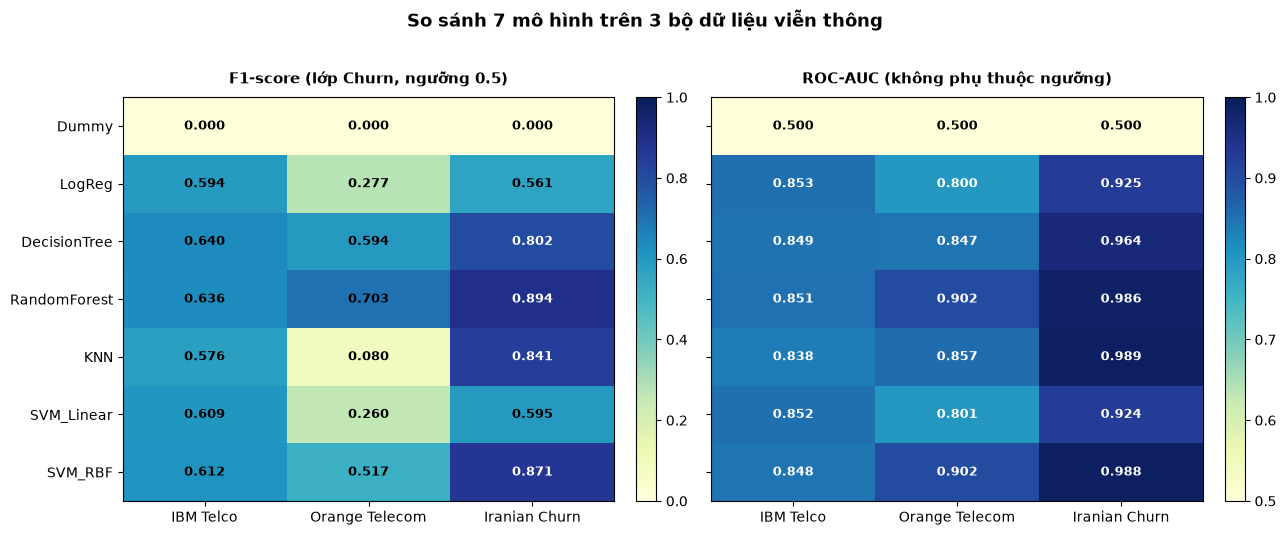

Saved: C:\Users\nguye\OneDrive\Documents\NMKPDL_HM\projectML\figures\models\heatmap_f1_roc_auc.png


In [4]:
model_order = ['Dummy', 'LogReg', 'DecisionTree', 'RandomForest', 'KNN', 'SVM_Linear', 'SVM_RBF']
dataset_order = ['ibm', 'orange', 'iranian']
dataset_labels = {'ibm': 'IBM Telco', 'orange': 'Orange Telecom', 'iranian': 'Iranian Churn'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for ax, metric, title in [
    (axes[0], 'f1_churn', 'F1-score (lớp Churn, ngưỡng 0.5)'),
    (axes[1], 'roc_auc', 'ROC-AUC (không phụ thuộc ngưỡng)'),
]:
    pivot = long_df.pivot(index='model', columns='dataset', values=metric)
    pivot = pivot.reindex(index=[m for m in model_order if m in pivot.index],
                          columns=[d for d in dataset_order if d in pivot.columns])
    data = pivot.to_numpy(dtype=float)
    im = ax.imshow(data, cmap='YlGnBu', aspect='auto', vmin=0.0 if metric == 'f1_churn' else 0.5, vmax=1.0)
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels([dataset_labels.get(c, c) for c in pivot.columns], fontsize=10)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index, fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold', pad=10)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            val = data[i, j]
            txt_color = 'white' if val > 0.72 else 'black'
            ax.text(j, i, f'{val:.3f}', ha='center', va='center', color=txt_color, fontsize=9.5, fontweight='bold')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle('So sánh 7 mô hình trên 3 bộ dữ liệu viễn thông', fontsize=13, fontweight='bold', y=1.02)
fig.tight_layout()
heatmap_path = FIGURES_DIR / 'heatmap_f1_roc_auc.png'
fig.savefig(heatmap_path, dpi=200, bbox_inches='tight')
plt.show()
print('Saved:', heatmap_path)

## 4. Độ ổn định 10 seed (`mean ± std`) — 4 độ đo chính

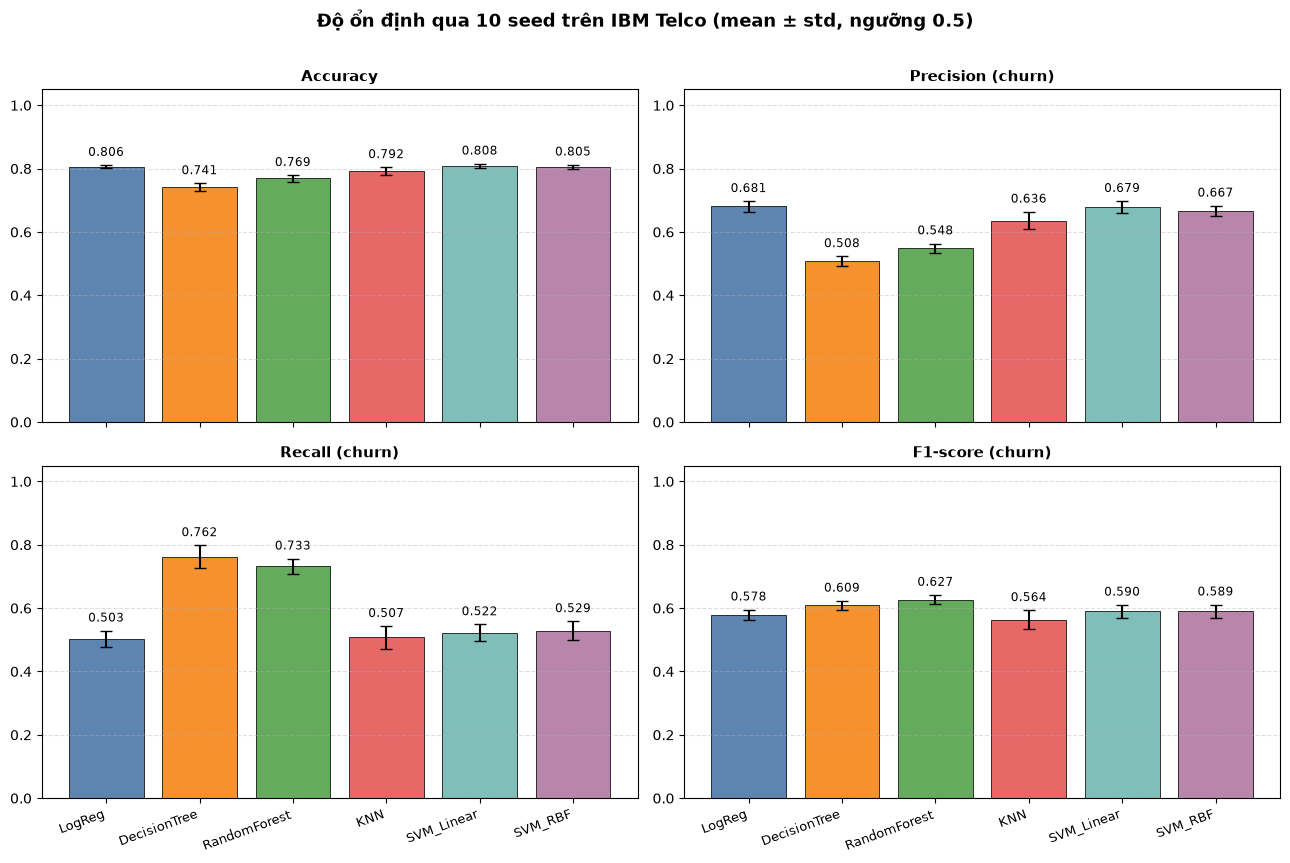

Saved: C:\Users\nguye\OneDrive\Documents\NMKPDL_HM\projectML\figures\models\stability_4metrics_ibm.png


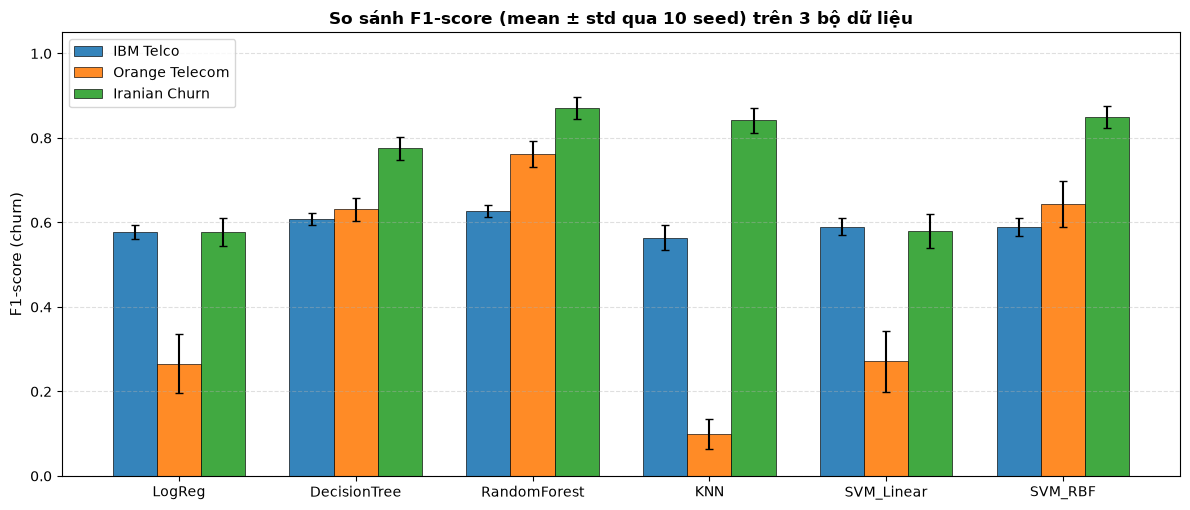

Saved: C:\Users\nguye\OneDrive\Documents\NMKPDL_HM\projectML\figures\models\stability_f1_3datasets.png


In [5]:
stab_df = pd.read_csv(stability_csv)
real_models = ['LogReg', 'DecisionTree', 'RandomForest', 'KNN', 'SVM_Linear', 'SVM_RBF']
metrics_4 = [
    ('accuracy', 'Accuracy'),
    ('precision_churn', 'Precision (churn)'),
    ('recall_churn', 'Recall (churn)'),
    ('f1_churn', 'F1-score (churn)'),
]

sub = stab_df[stab_df['dataset'] == PRIMARY_DATASET].copy()
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True)
colors = ['#4C78A8', '#F58518', '#54A24B', '#E45756', '#72B7B2', '#B279A2']

for ax, (m_key, m_label) in zip(axes.flat, metrics_4):
    m_sub = sub[sub['metric'] == m_key].set_index('model').reindex(real_models)
    x = np.arange(len(real_models))
    bars = ax.bar(x, m_sub['mean'], yerr=m_sub['std'], capsize=4, color=colors, alpha=0.9, edgecolor='black', linewidth=0.6)
    ax.set_title(m_label, fontsize=11, fontweight='bold')
    ax.set_ylim(0, 1.05)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels(real_models, rotation=20, ha='right', fontsize=9.5)
    for bar, mean_v, std_v in zip(bars, m_sub['mean'], m_sub['std']):
        ax.text(bar.get_x() + bar.get_width() / 2, mean_v + std_v + 0.02,
                f'{mean_v:.3f}', ha='center', va='bottom', fontsize=8.5)

fig.suptitle(f'Độ ổn định qua 10 seed trên {dataset_labels.get(PRIMARY_DATASET, PRIMARY_DATASET)} (mean ± std, ngưỡng 0.5)',
             fontsize=13, fontweight='bold', y=1.01)
fig.tight_layout()
stab_path = FIGURES_DIR / f'stability_4metrics_{PRIMARY_DATASET}.png'
fig.savefig(stab_path, dpi=200, bbox_inches='tight')
plt.show()
print('Saved:', stab_path)

# Biểu đồ F1 (churn) mean ± std trên cả 3 dataset
f1_all = stab_df[stab_df['metric'] == 'f1_churn']
fig2, ax2 = plt.subplots(figsize=(12, 5.2))
width = 0.25
x = np.arange(len(real_models))
for idx, ds in enumerate(dataset_order):
    ds_sub = f1_all[f1_all['dataset'] == ds].set_index('model').reindex(real_models)
    offset = (idx - 1) * width
    ax2.bar(x + offset, ds_sub['mean'], width=width, yerr=ds_sub['std'], capsize=3,
            label=dataset_labels.get(ds, ds), alpha=0.9, edgecolor='black', linewidth=0.5)
ax2.set_xticks(x)
ax2.set_xticklabels(real_models, fontsize=10)
ax2.set_ylim(0, 1.05)
ax2.set_ylabel('F1-score (churn)', fontsize=10.5)
ax2.set_title('So sánh F1-score (mean ± std qua 10 seed) trên 3 bộ dữ liệu', fontsize=12, fontweight='bold')
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.4)
fig2.tight_layout()
f1_3ds_path = FIGURES_DIR / 'stability_f1_3datasets.png'
fig2.savefig(f1_3ds_path, dpi=200, bbox_inches='tight')
plt.show()
print('Saved:', f1_3ds_path)

## 5. Kiểm định thống kê (Random Forest vs mô hình mạnh nhất còn lại)

In [6]:
stat_df = pd.read_csv(stat_tests_csv)
stat_df

,dataset,test,scope,rf_mean,rival,rival_mean,statistic,p_value,n_pairs
0,ibm,corrected_t_average_precision,ranking (threshold-free),0.6644,LogReg,0.6682,-0.9318,0.376000,10
1,ibm,corrected_t_roc_auc,ranking (threshold-free),0.8444,LogReg,0.8457,-0.624,0.548000,10
2,ibm,corrected_t_f1_churn,operating point @0.5,0.6270,LogReg,0.5784,5.5729,0.000346,10
3,ibm,wilcoxon_average_precision,ranking (threshold-free),0.6644,LogReg,0.6682,14.5,0.201000,10
4,ibm,wilcoxon_roc_auc,ranking (threshold-free),0.8444,LogReg,0.8457,17.0,0.322000,10
5,ibm,wilcoxon_f1_churn,operating point @0.5,0.6270,LogReg,0.5784,0.0,0.001950,10
6,ibm,mcnemar_accuracy_seed42,operating point @0.5,0.7682,LogReg,0.8070,"b=66, c=107",0.002260,1057
7,orange,corrected_t_average_precision,ranking (threshold-free),0.8357,DecisionTree,0.7617,3.039,0.014000,10
8,orange,corrected_t_roc_auc,ranking (threshold-free),0.9085,DecisionTree,0.8839,1.1134,0.294000,10
9,orange,corrected_t_f1_churn,operating point @0.5,0.7617,DecisionTree,0.6314,8.918,0.000009,10
